<a href="https://colab.research.google.com/github/carn51/Assignment-1/blob/main/LATEST_251026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## First row of dropcols are permanent

In [8]:
df = pd.DataFrame(pd.read_csv('/content/Schizophrenia_Dataset(5)(1).csv')).drop(columns=['Tired', 'Participant', 'Focus', 'Tension', 'Pregnant',
                                                                                         'Race'])    #back to default
df.head()

,Diagnosis,Anhedonia,Apathy,Appetite,Concentration,Content,Delay,Delusion,Dep_Mood,Hallucination,...,Intrusive_Thoughts,Passive,Psychomotor,Rumination,Sex,Sleep,Stress,Suspicious,Unusual_Thought,Withdrawal
0,1,4.501446,3.056575,9.283891,8.305502,0.006142,Yes,1.170842,8.177884,12.831823,...,6.648416,4.385417,3.854579,5.041432,Female,6.552082,5.915492,3.991749,3.744410,5.242819
1,0,5.432608,0.307721,25.809400,5.060206,0.062209,Yes,2.272548,11.162913,38.979963,...,4.873116,2.491285,5.821110,4.656790,Male,5.558434,4.008265,NaN,0.720458,3.797242
2,0,6.557500,-1.412208,24.842012,6.504229,0.071532,No,1.439095,5.887363,11.296530,...,7.924018,-999.000000,7.893102,7.290494,Female,5.787561,7.177926,NaN,-0.491255,4.421288
3,0,5.429568,1.686157,24.175853,6.994948,0.278345,No,1.380185,8.943851,4.237368,...,NaN,-999.000000,3.812874,6.759339,Female,6.787287,2.866815,NaN,0.765388,2.299562
4,1,5.099846,-0.612506,45.808490,5.869212,0.004214,Yes,1.237976,6.741627,0.863636,...,5.650523,7.999254,5.119658,6.190019,Male,7.748312,6.798220,5.103103,0.705895,6.547707


In [9]:
#plt.boxplot(df['Hallucination'])

In [10]:
df.dtypes

,0
Diagnosis,int64
Anhedonia,float64
Apathy,float64
Appetite,float64
Concentration,float64
Content,float64
Delay,object
Delusion,float64
Dep_Mood,float64
Hallucination,float64


missingness analysis, justify simpleimputer

In [11]:
df.isnull().sum()

,0
Diagnosis,0
Anhedonia,0
Apathy,0
Appetite,0
Concentration,0
Content,0
Delay,0
Delusion,0
Dep_Mood,0
Hallucination,0


In [12]:
#build missingness
#indices_itt = df.loc[np.where(df['Intrusive_Thoughts'].isna())]
#indices_pregnant = df.loc[np.where(df['Pregnant'].isna())]
#indices_sus = df.loc[np.where(df['Suspicious'].isna())]

#overlap = pd.Series(indices).value_counts()
#missingness_df0 =  pd.concat([indices_itt, indices_pregnant, indices_sus])
#missingness_df = missingness_df0.drop_duplicates()
#missingness_df

In [13]:
#difference is area might show

#dfm = df[[col for col in df.columns if df[col].nunique() > 5]]

#for col in dfm.drop(columns = ['Intrusive_Thoughts', 'Suspicious']):
 # plt.title(f'Missingness Comparison: {col}')
  #plt.hist(df[col], bins=20, alpha = 0.6, label = 'No Missingness')
  #plt.hist(missingness_df[col], bins = 20, alpha = 0.6, label = 'Missingness')
 # plt.grid(alpha = 0.3)
  #plt.xlabel(f'{col} Score')
 # plt.ylabel('Frequency')
  #plt.legend(shadow = True)
 # plt.show()

#SHAPE not necessarily size... df lens differ
#pay attenion to axes

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
#for impoertances
from sklearn.ensemble import RandomForestClassifier

Outlier analysis... extend

In [15]:
#initial, loose grouping of numerical and categorical based on number of unique values
numcols_strings = [col for col in df.columns if df[col].nunique() > 6]
numdf = df[numcols_strings]
#print(numdf.dtypes)

def outlier_frequency_func(numdf, p1 = 25, p2 = 75):
  ### docstring here ###
  for col in numdf:
    #plt.title(f'Outlier Screening:  {col}')
    #plt.boxplot(df[col])
    #plt.show()

    col_outliers = []

    for i, val in enumerate(numdf[col]):
      if (val < np.percentile(numdf[col], 25)) or (val > np.percentile(numdf[col], 75)):
        col_outliers.append(i)

  #values count for each shows how many times each row has an outlier overall
  outlier_row_count = pd.Series(col_outliers).value_counts()
  return outlier_row_count

#mask takes OUT those that don't fit condition, replacing with nan --> use dropna
orc = pd.DataFrame(outlier_frequency_func(numdf))
print(orc)
outlier_present_mask = orc.mask(orc.values <= 2).dropna()
#it appears there are no rows with 2+ outliers... seems unlikely
#CHECK
max(orc)    #is 1... unrealistic, mention to John, len 2500: half have a single

orc.index.nunique()

df_outlier = df.iloc[orc.index]

      count
4999      1
0         1
3         1
4         1
4937      1
...     ...
19        1
20        1
23        1
24        1
26        1

[2500 rows x 1 columns]


VIF also multicorr

<Axes: >

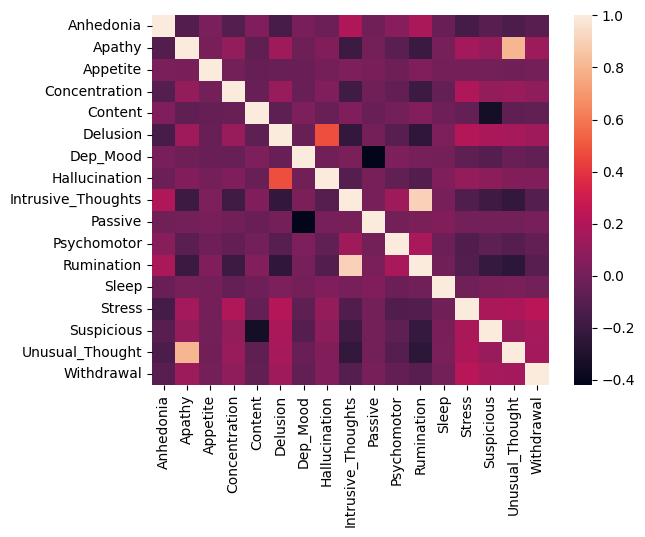

In [16]:
sns.heatmap(df_outlier.drop(columns= ['Diagnosis']).select_dtypes(include = ['number']).corr())

## **OUTLIERS REMOVAL**.. add obervations, justify ignoring (or not)

In [17]:
def outliers_out(df):

  col_outliers = []

  numdf = df.select_dtypes(include = ['number'])

  for col in numdf:
    for i, val in enumerate(numdf[col]):
      #slightly more lenient params ... 5, 95
      if (val < np.percentile(numdf[col], 5)) or (val > np.percentile(numdf[col], 95)):
        col_outliers.append(i)

  return col_outliers

In [18]:
#df = df.drop(outliers_out(df), axis = 0)

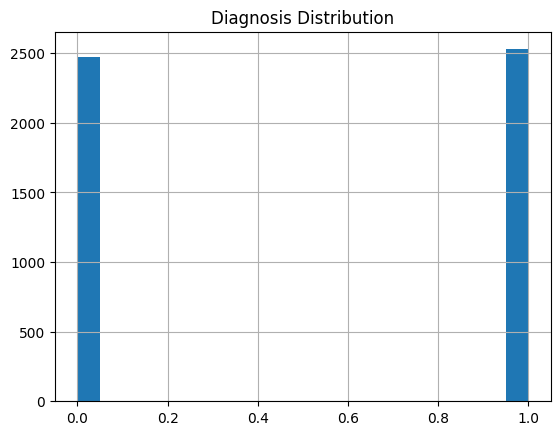

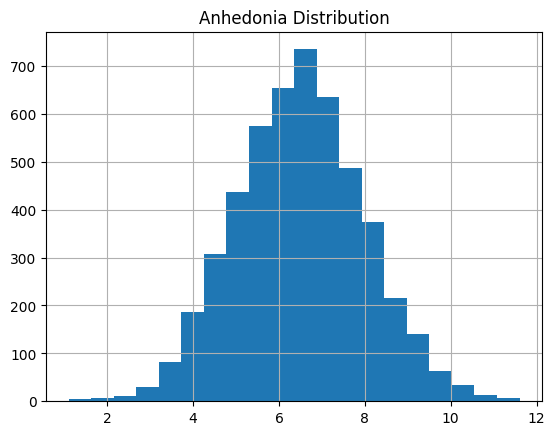

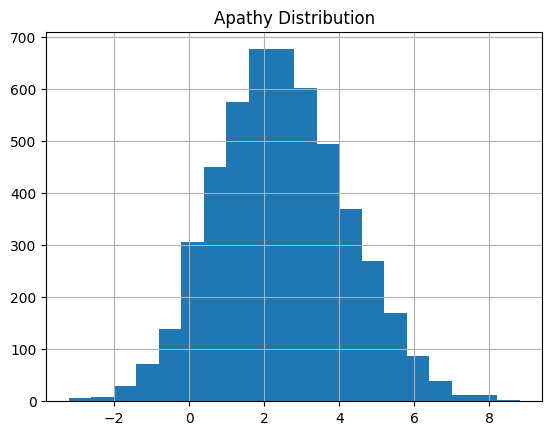

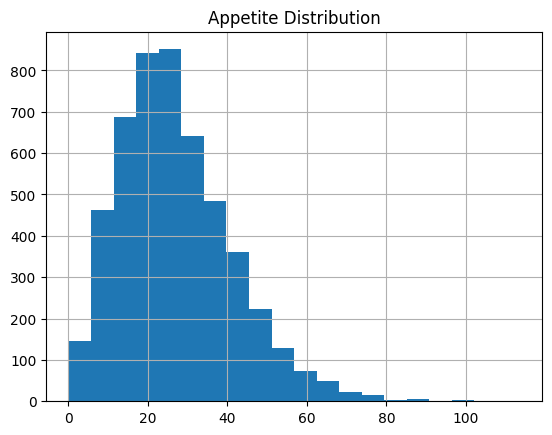

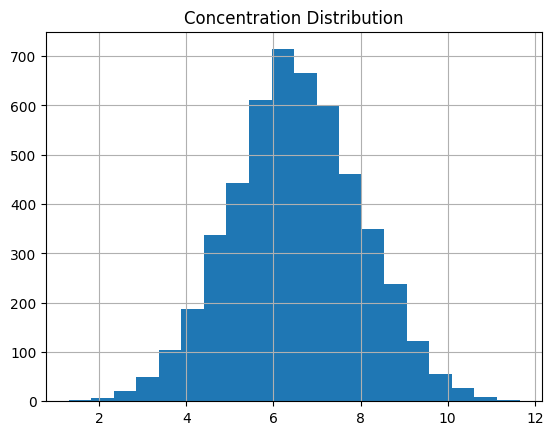

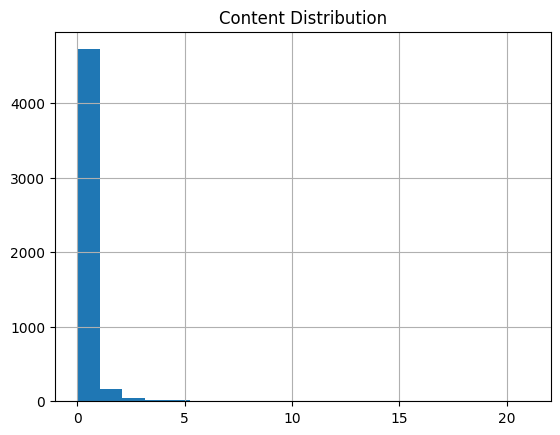

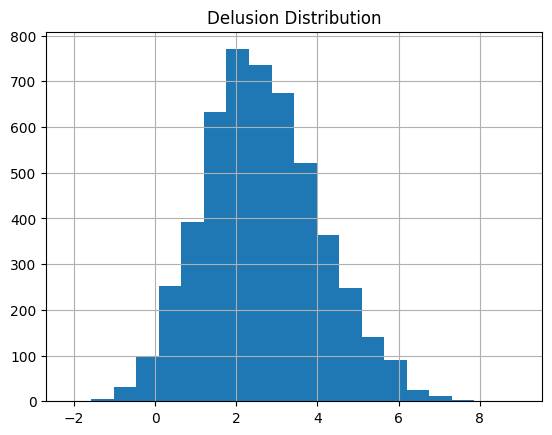

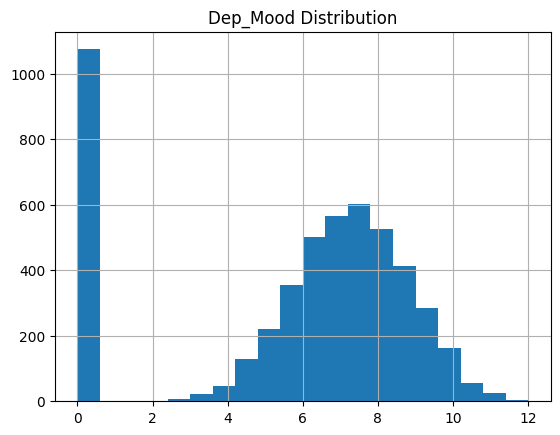

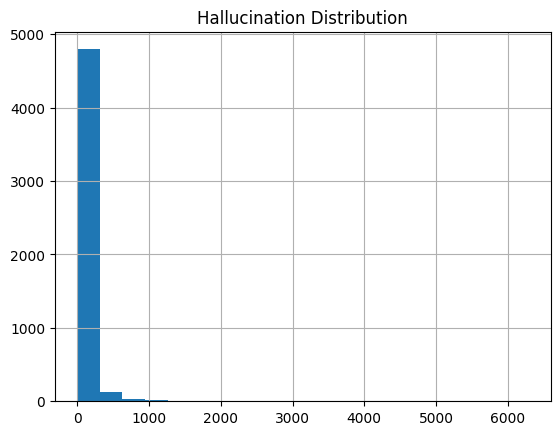

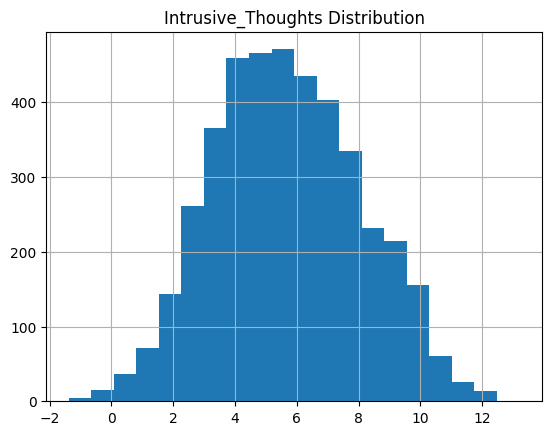

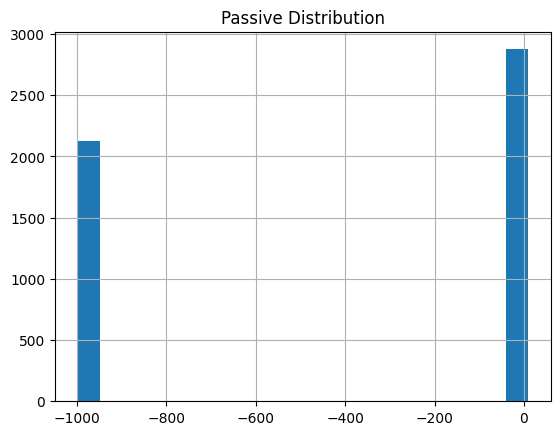

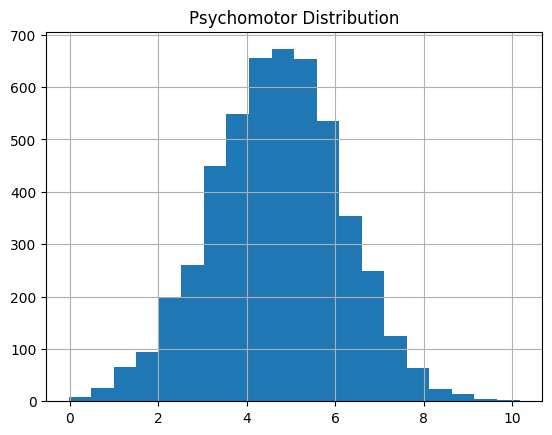

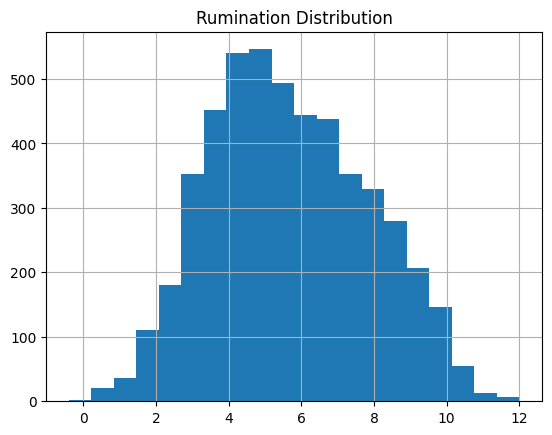

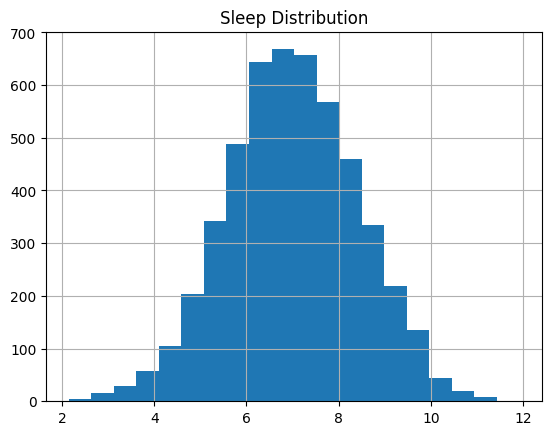

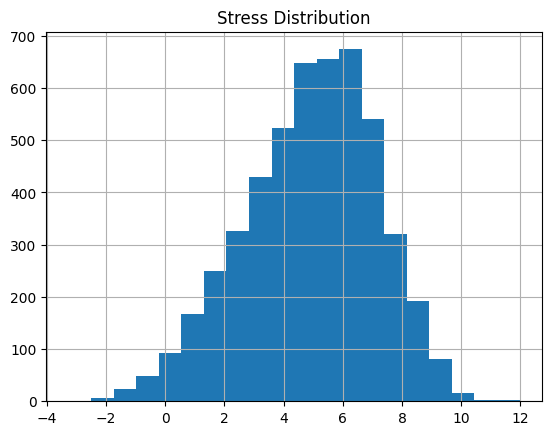

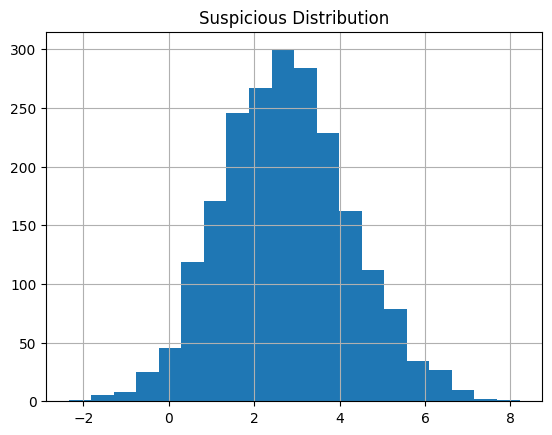

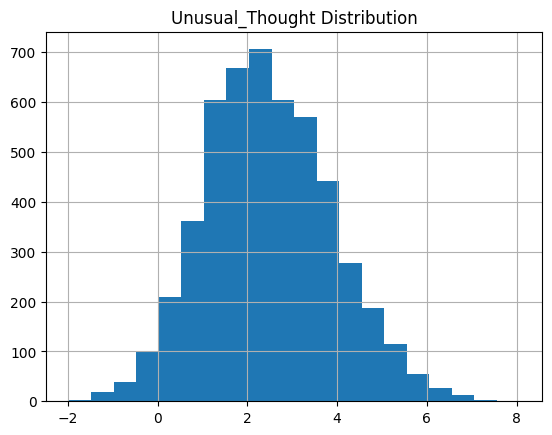

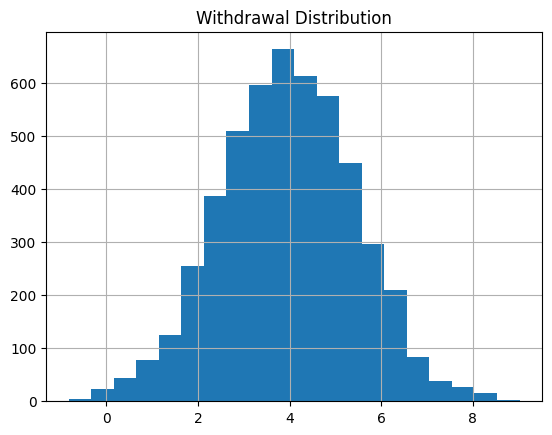

In [19]:
for var in df.select_dtypes(include = ['number']):
  plt.title(f'{var} Distribution')
  df[var].hist(bins = 20)
  plt.show()

Multicorr

<Axes: >

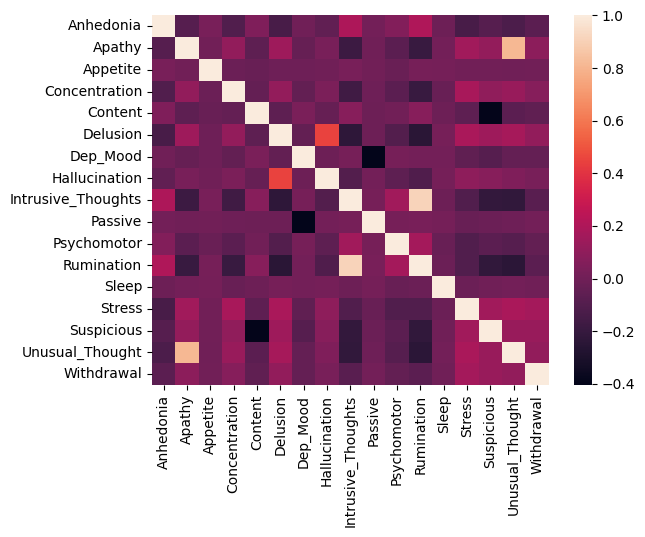

In [20]:
sns.heatmap(df.drop(columns = ['Diagnosis']).select_dtypes(include = 'number').corr())

In [21]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score

In [25]:
def vnn(df):#, input_cols):

  #prep in here now... may change for other models
  y = df['Diagnosis']
  X = df.drop(columns = ['Diagnosis', 'Delusion', 'Rumination'])

  X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=23)
  X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=23)

  num = df[[col for col in X.columns if df[col].nunique() > 6]].columns
  cat = df[[col for col in X.columns if df[col].nunique() <= 6]].columns

  pcat = Pipeline(steps = [('imp_cat', SimpleImputer(strategy='most_frequent')),
                         ('encoder', OneHotEncoder(sparse_output=False))])
  pnum = Pipeline(steps = [('num_imp', SimpleImputer()),
                         ('scaler', StandardScaler())])
  prep = ColumnTransformer(transformers = [('num_prep', pnum,num ),
                                         ('cat_prep', pcat, cat)]).set_output(transform='pandas')
  final_pipe = Pipeline(steps = [('prep_pipe', prep)]).set_output(transform = 'pandas')

  final_pipe.fit(X_train, y_train)

  #print(final_pipe[-1])

  colnames = final_pipe[-1].get_feature_names_out()

  X_train_prep = final_pipe.fit_transform(X_train)

  X_test_prep = final_pipe.transform(X_test)
  X_val_prep = final_pipe.transform(X_val)

  #tensor
  X_train_tensor = torch.tensor(X_train_prep.values, dtype = torch.float32)
  X_test_tensor = torch.tensor(X_test_prep.values, dtype = torch.float32)
  X_val_tensor = torch.tensor(X_val_prep.values, dtype = torch.float32)
  y_train_tensor = torch.tensor(y_train.values, dtype = torch.long)
  y_test_tensor = torch.tensor(y_test.values, dtype = torch.long)
  y_val_tensor = torch.tensor(y_val.values, dtype = torch.long)

  class VanillaNeuralNetwork(nn.Module):
    def __init__(self):
      super(VanillaNeuralNetwork, self).__init__()

      self.fc1 =  nn.Linear(len(X_test_prep.columns), 100)
      self.relu1 = nn.ReLU()
      self.fc2 = nn.Linear(100, 25)
      self.relu2 = nn.ReLU()
      self.fc3 = nn.Linear(25, 2)
      self.sigmoid = nn.Sigmoid()

    def forward(self, x):
      #x = torch.tensor(x)
      x = self.fc1(x)
      x= self.relu1(x)
      #add dropout layer
      #x = self.dropout(x)
      x = self.fc2(x)
      x = self.relu2(x)
      x = self.fc3(x)
      x = self.sigmoid(x)
      return x

  model = VanillaNeuralNetwork()

  loss_list = []
  val_loss_list = []
  acc_list = []

  loss_func = torch.nn.CrossEntropyLoss()
  #momentum can be adjusted here
  opt = optim.Adam(model.parameters(), lr= 0.0018)#, betas = (0.9, 0.999))
  num_epochs = 200

  #batch should be tensors

  for epoch in range(num_epochs):
    opt.zero_grad()
    preds = model(X_test_tensor)
    loss = loss_func(preds, y_test_tensor)
    loss.backward()
    opt.step()
    loss_list.append(loss.item())

    val_hat = model(X_val_tensor)
    val_loss_list.append(loss_func(val_hat, y_val_tensor))#.detach().numpy())

    acc_list.append(accuracy_score([1 if val > 0.9 else 0 for val in preds[:, 1]], y_test))

  return [preds, loss_list, val_loss_list, y_test]    #same line or diff?

  #return loss_list, val_loss_list

In [26]:
#len(vnn(df, input_cols=23)[2])

def val_loss_format_func(df):#, input_cols):
  """ converts list of tensors to python list, made for vanilla_nn() output"""
  vl2 = []
  for num in range(0, 199):
    vl2.append(vnn(df)[2][num])
  vl3 = [vl.detach().numpy() for vl in vl2]
  vl4 = [vl3.tolist() for vl3 in vl3]
  return vl4

#vlff_input = val_loss_format_func(vnn(df)[2])#, input_cols=22)

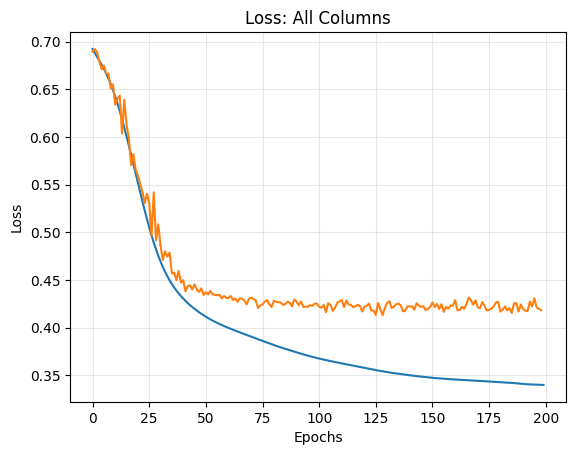

In [27]:
plt.title('Loss: All Columns')

###########################################################################
pd.Series(vnn(df)[1]).plot()
#################################################################################
pd.Series(val_loss_format_func(df)).plot()
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.grid(alpha = 0.3)
plt.show()

OVERFITTING

Importances (static)

In [ ]:
#from sklearn.ensemble import RandomForestClassifier
#no cat... justify
#rf = RandomForestClassifier(random_state=23)
#rf.fit(X_train.select_dtypes(include = ['number']), y_train)
#rf_pred = rf.predict(X_test.select_dtypes(include = ['number']))
#list(sorted(zip(rf.feature_importances_, rf.feature_names_in_)))

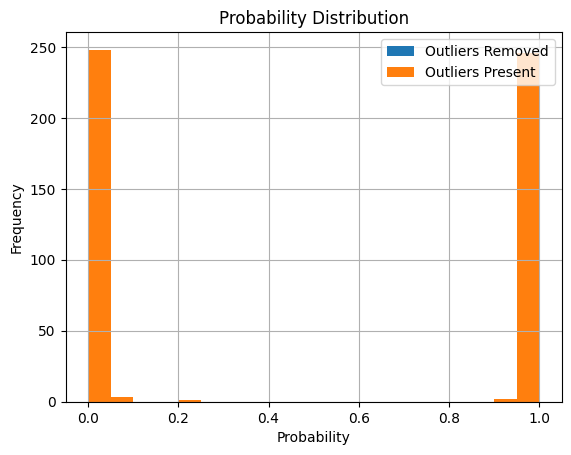

In [28]:
preds = vnn(df)[0]#, input_cols=20)[0]
plt.title('Probability Distribution')
pd.Series(preds[:, 1].detach().numpy()).hist(bins = 20, label = 'Outliers Removed')
pd.Series(preds[:, 1].detach().numpy()).hist(bins = 20, label = 'Outliers Present')

plt.xlabel('Probability')
plt.ylabel('Frequency')
plt.legend(loc = 'upper right')
plt.show()

Threshold and scoring

In [30]:
preds_for_metric = [1 if val > 0.9 else 0 for val in preds[:, 1]]
#print(preds_for_metric)

y_test = vnn(df)[3]

print(accuracy_score(preds_for_metric, y_test))

from sklearn.metrics import recall_score
print(round(recall_score(preds_for_metric, y_test), 3))

from sklearn.metrics import precision_score
print(round(precision_score(preds_for_metric, y_test), 3))

0.97
0.972
0.968


Creating function

In [31]:
def drop_col_func(df):    #input_col dropped
  """ keep col phrase: STR"""

  col_phrase_list_drop = vnn(df)[1]
  vl_col_phrase_list_drop = val_loss_format_func(df)

  col_phrase_list_loss = pd.Series(col_phrase_list_drop)
  col_phrase_list_vl_drop = pd.Series(vl_col_phrase_list_drop)

  plt.title(f'Momentum + Dropout')    #CHANGE
  col_phrase_list_loss.plot()
  col_phrase_list_vl_drop.plot()
  plt.grid(alpha = 0.3)
  #fixing ylim a good idea
  plt.ylim(.3, .7)
  plt.show()



  preds_for_metric_col_phrase_list_drop = [1 if val > 0.8 else 0 for val in preds[:, 1]]
  return [accuracy_score(preds_for_metric_col_phrase_list_drop, y_test), ]

Testing USE THIS:

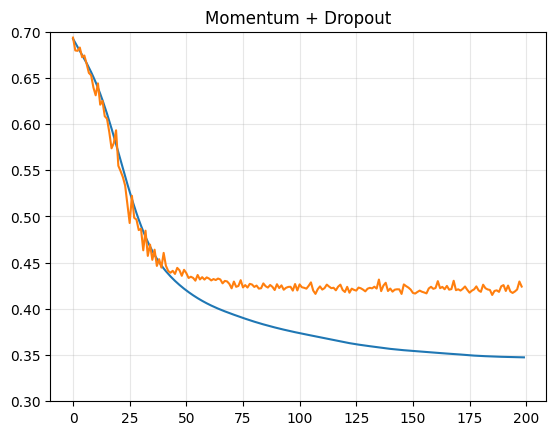

[0.97]

In [32]:
drop_col_func(df)

ROC curve

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc

In [34]:
vnn(df)[3].dtype
print(vnn(df)[3])

4642    1
2007    0
311     0
4433    1
3463    0
       ..
2592    1
4695    1
1397    1
3252    0
1073    0
Name: Diagnosis, Length: 500, dtype: int64


In [35]:
preds_prob = vnn(df)[0][:, 1].detach().numpy()

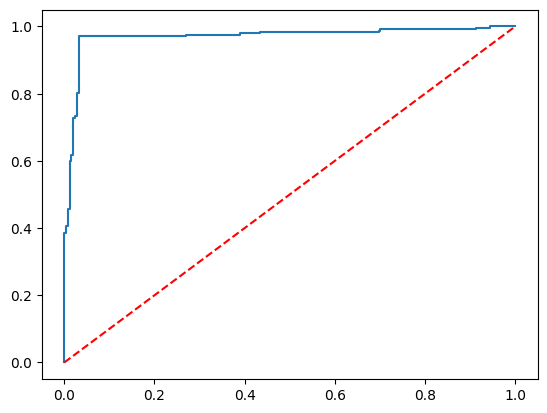

In [36]:
#get PROBS NOT 0 or 1
fpr, tpr, thresholds = roc_curve(vnn(df)[3], preds_prob)

roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f'(AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'r--', label='Random Guess')
plt.show()

Final graph: outliers need removal!!!

In [ ]:
acc_list_v0 = [0.944, 0.93, 0.932, 0.944, 0.936, 0.918, 0.918, 0.918, 0.916, 0.914, 0.9, 0.906, 0.91, 0.904,
            0.888, 0.894]
acc_list_v1_dropout = [0.93, 0.93, 0.914, 0.924, 0.91, 0.92, 0.91, 0.9, 0.904, 0.918, 0.918, 0.896, 0.898,
                       0.906, 0.902, 0.868, 0.882]
acc_list_v2_dropout_momentum = [0.938, 0.926, 0.922, 0.906, 0.916, 0.912, 0.914, 0.908, 0.914, 0.906, 0.906, 0.9,
                                0.892, 0.888, 0.904, 0.868, 0.868]

plt.title('Vanilla NN: Accuracy With Variable Removal')
plt.plot(acc_list_v0, label = 'Vanilla NN v0', color = 'indianred')
plt.plot(acc_list_v1_dropout, label = 'VNN: Dropout', color = 'pink')
plt.plot(acc_list_v2_dropout_momentum, label = 'VNN: Dropout and Momentum', color = 'violet')

plt.legend(shadow  = True)
plt.grid(alpha = 0.25)
plt.ylabel('Accuracy')
plt.xticks()
plt.ylim(0.85, 1)

In [ ]:
#final recall plot?

Graph

In [ ]:
import networkx as nx